In [1]:
import pandas as pd
import zipfile
import os
import glob
import geopandas as gpd
import rasterio
from rasterio.plot import show
import matplotlib.pyplot as plt
import time
from pygbif import occurrences as occ
import geodatasets

C:\Users\hibah\anaconda3\envs\spatial_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:

# 1. Set your GBIF credentials as environment variables
os.environ['GBIF_USER'] = ''
os.environ['GBIF_PWD'] = ''
os.environ['GBIF_EMAIL'] = ''

# 2. Kick off the download job

download_key = occ.download(['taxonKey = 2925303', 'hasCoordinate = TRUE'])[0]
print(f"Request accepted! Your Download Key is: {download_key}")

# 3. Monitor the download status
print("Waiting for GBIF servers to compile the file. This may take several minutes...")
while True:
    meta = occ.download_meta(key=download_key)
    status = meta['status']
    print(f"Current status: {status}")
    
    # Break the loop if the job is finished or failed
    if status in ['SUCCEEDED', 'KILLED', 'CANCELLED', 'FAILED']:
        break
        
    # Wait 30 seconds before checking again so we do not overwhelm the server
    time.sleep(30)

# 4. Download the file to your computer
if status == 'SUCCEEDED':
    print("Compilation complete. Downloading the ZIP file now...")
   
    occ.download_get(key=download_key, path='.')
    print("Download successful! The ZIP file is in your current folder.")
else:
    print(f"The download did not finish successfully. Final status: {status}")'''

'\n# 1. Set your GBIF credentials as environment variables\n# Replace these strings with your actual GBIF account details\nos.environ[\'GBIF_USER\'] = \'hibah\'\nos.environ[\'GBIF_PWD\'] = \'\'\nos.environ[\'GBIF_EMAIL\'] = \'hibahpatanwala12@gmail.com\'\n\nprint("Sending download request to GBIF...")\n\n# 2. Kick off the download job\n# We pass the taxonKey for Lantana camara and ensure they have coordinates\n# The Fix: Add [0] to extract just the string\ndownload_key = occ.download([\'taxonKey = 2925303\', \'hasCoordinate = TRUE\'])[0]\nprint(f"Request accepted! Your Download Key is: {download_key}")\n\n# 3. Monitor the download status\n# Retrieves the occurrence download metadata by its unique key\nprint("Waiting for GBIF servers to compile the file. This may take several minutes...")\nwhile True:\n    meta = occ.download_meta(key=download_key)\n    status = meta[\'status\']\n    print(f"Current status: {status}")\n\n    # Break the loop if the job is finished or failed\n    if stat

In [3]:
gbif_lantana_data = r"C:/Users/hibah/rd/0002512-260803105813674.csv"
extract_folder = "gbif_lantana_data"

# Read the file using pandas
df_full = pd.read_csv(gbif_lantana_data, sep='\t', low_memory=False)

# 3. Filter out records missing latitude/longitude coordinates
df_clean = df_full.dropna(subset=['decimalLongitude', 'decimalLatitude']).copy()

# Rename columns to match the plotting code
df_clean.rename(columns={'decimalLongitude': 'longitude', 'decimalLatitude': 'latitude'}, inplace=True)

print(f"Total occurrences loaded: {len(df_clean)}")

# Save to a clean CSV for mapping
df_clean[['longitude', 'latitude', 'species', 'countryCode']].to_csv("lantana_full_dataset.csv", index=False)

Total occurrences loaded: 122754


C:\Users\hibah\anaconda3\envs\spatial_env\Lib\site-packages\matplotlib\colors.py:824: RuntimeWarning: overflow encountered in multiply
  xa *= self.N
C:\Users\hibah\anaconda3\envs\spatial_env\Lib\site-packages\matplotlib\colors.py:824: RuntimeWarning: overflow encountered in multiply
  xa *= self.N


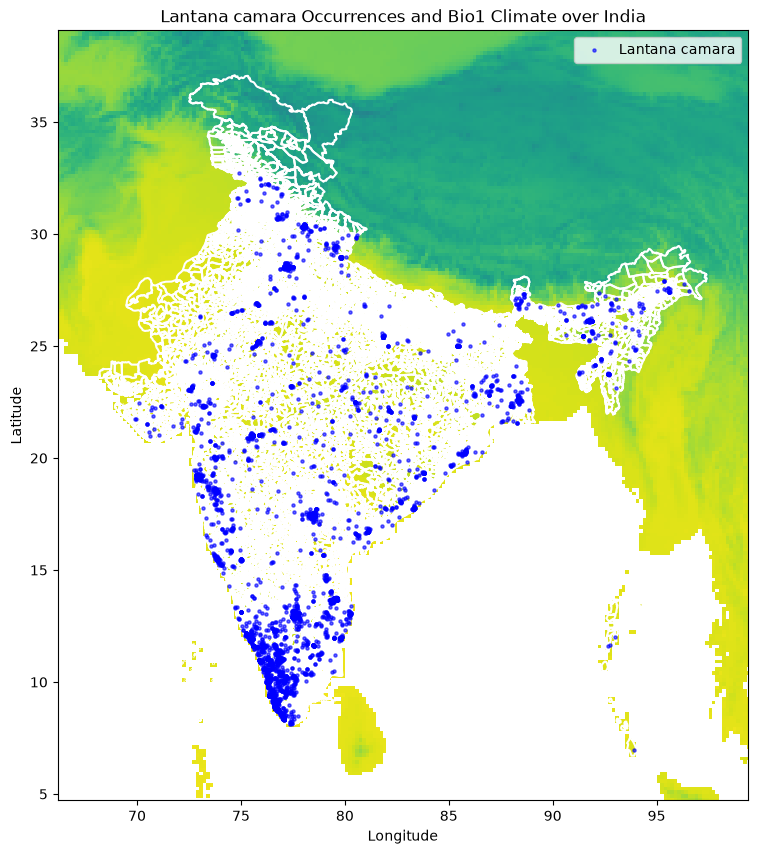

5643


In [4]:


# 1. Load all three datasets
# Make sure to update the paths to match your actual file locations
background_tif = r"rd\image\wc2.1_10m_bio_1.tif"
india_geojson = gpd.read_file(r"C:/Users/hibah/rd/INDIAN_PINCODE_BOUNDARY.geojson")


df = pd.read_csv("lantana_full_dataset.csv")
df_india = df[df['countryCode'] == 'IN']
# Ensure the GeoJSON matches the raster's coordinate system (standard Long/Lat)
india_geojson = india_geojson.to_crs("EPSG:4326")

# 2. Set up the figure
fig, ax = plt.subplots(figsize=(12, 10))

# 3. Layer 1 (Bottom): The background climate raster
with rasterio.open(background_tif) as src:
    show(src, ax=ax, cmap='viridis', zorder=1)

# 4. Layer 2 (Middle): The India GeoJSON boundary
# facecolor="none" ensures the inside is transparent so the climate data shows through
india_geojson.plot(ax=ax, facecolor="none", edgecolor='white', linewidth=1.5, zorder=2)

# 5. Layer 3 (Top): The Lantana camara occurrences
ax.scatter(df_india['longitude'], df_india['latitude'], 
           color='blue', 
           marker='.', 
           alpha=0.6,    # Slight transparency
           s=20,         # Size of the dots
           zorder=3,     # Keeps dots on top of the map and boundary lines
           label='Lantana camara')

# 6. Zoom in on India
# We extract the bounding box coordinates from the GeoJSON to crop the visual area
minx, miny, maxx, maxy = india_geojson.total_bounds

# Apply the limits, adding a 2-degree padding so the map isn't squeezed to the edge
ax.set_xlim(minx - 2, maxx + 2)
ax.set_ylim(miny - 2, maxy + 2)

# 7. Finalize and show the plot
plt.title("Lantana camara Occurrences and Bio1 Climate over India")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.show()
print(len(df[df["countryCode"]=="IN"]))

Total points strictly inside Maharashtra: 428


C:\Users\hibah\anaconda3\envs\spatial_env\Lib\site-packages\matplotlib\colors.py:824: RuntimeWarning: overflow encountered in multiply
  xa *= self.N
C:\Users\hibah\anaconda3\envs\spatial_env\Lib\site-packages\matplotlib\colors.py:824: RuntimeWarning: overflow encountered in multiply
  xa *= self.N
C:\Users\hibah\anaconda3\envs\spatial_env\Lib\site-packages\matplotlib\colors.py:824: RuntimeWarning: overflow encountered in multiply
  xa *= self.N


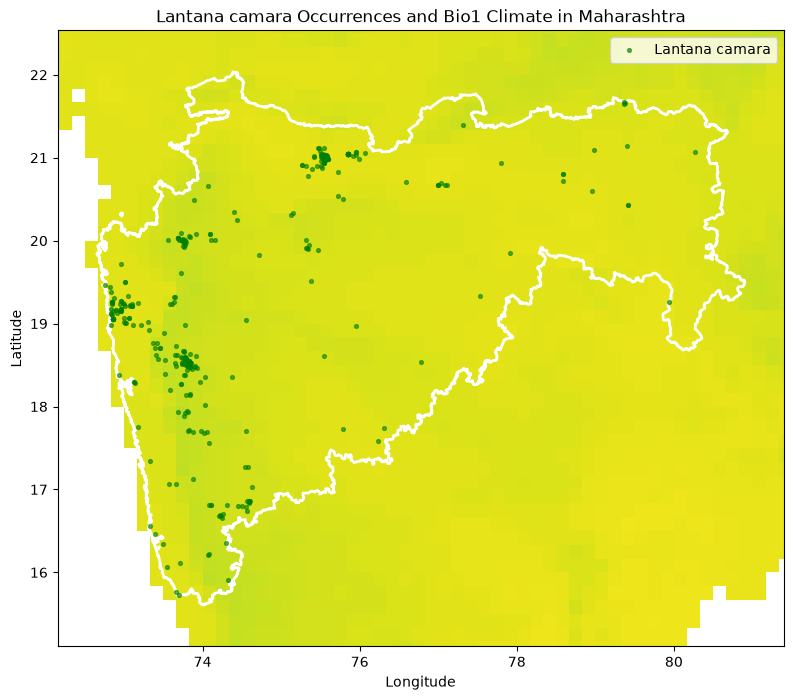

In [5]:
# 1. Load your datasets
background_tif = r"C:\Users\hibah\rd\image\wc2.1_10m_bio_1.tif"
df = pd.read_csv("lantana_full_dataset.csv")

# 2. Load the Maharashtra GeoJSON boundary
# If you have a specific Maharashtra file:
maharashtra_geojson = gpd.read_file(r"C:/Users/hibah/rd/MAHARASHTRA_STATE.geojson")

maharashtra_geojson = maharashtra_geojson.to_crs("EPSG:4326")
import geopandas as gpd
from shapely.geometry import Point

# 1. Convert your regular dataframe into a spatial GeoDataFrame
# We tell it which columns are the coordinates and set the CRS to match the map
gdf_points = gpd.GeoDataFrame(
    df, 
    geometry=gpd.points_from_xy(df['longitude'], df['latitude']),
    crs="EPSG:4326"
)

# 2. Clip the points! 
# This automatically deletes any point that falls outside the white polygon line
maharashtra_points = gpd.clip(gdf_points, maharashtra_geojson)


print(f"Total points strictly inside Maharashtra: {len(maharashtra_points)}")
# 3. Set up the plot
fig, ax = plt.subplots(figsize=(10, 8))

# Layer 1: Background Climate Map (Bio1)
with rasterio.open(background_tif) as src:
    show(src, ax=ax, cmap='viridis', zorder=1)

# Layer 2: Maharashtra Boundary
maharashtra_geojson.plot(ax=ax, facecolor="none", edgecolor='white', linewidth=2, zorder=2)

# 5. Layer 3 (Top): The clipped Lantana camara occurrences
# Notice we use maharashtra_points.plot instead of ax.scatter
maharashtra_points.plot(
    ax=ax, 
    color='green', 
    marker='.', 
    alpha=0.6, 
    markersize=30,  # Note: Geopandas uses 'markersize' instead of 's'
    zorder=3, 
    label='Lantana camara'
)

# 4. Zoom the map strictly to Maharashtra's borders
minx, miny, maxx, maxy = maharashtra_geojson.total_bounds

# Add a tiny bit of padding (e.g., 0.5 degrees) so the state isn't touching the edge of the image
ax.set_xlim(minx - 0.5, maxx + 0.5)
ax.set_ylim(miny - 0.5, maxy + 0.5)

# 5. Finalize the map
plt.title("Lantana camara Occurrences and Bio1 Climate in Maharashtra")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.show()


Total points strictly inside Maharashtra: 608


C:\Users\hibah\anaconda3\envs\spatial_env\Lib\site-packages\matplotlib\colors.py:824: RuntimeWarning: overflow encountered in multiply
  xa *= self.N
C:\Users\hibah\anaconda3\envs\spatial_env\Lib\site-packages\matplotlib\colors.py:824: RuntimeWarning: overflow encountered in multiply
  xa *= self.N
C:\Users\hibah\anaconda3\envs\spatial_env\Lib\site-packages\matplotlib\colors.py:824: RuntimeWarning: overflow encountered in multiply
  xa *= self.N


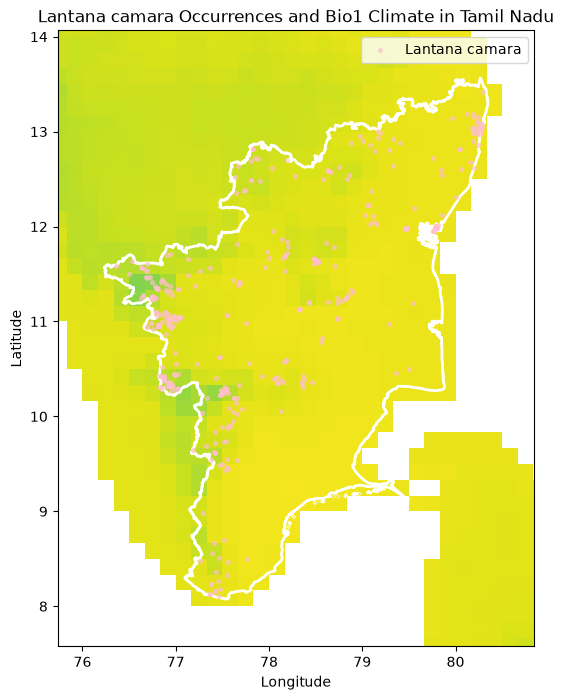

In [6]:
# 1. Load your datasets
background_tif = r"C:\Users\hibah\rd\image\wc2.1_10m_bio_1.tif"
df = pd.read_csv("lantana_full_dataset.csv")

# 2. Load the Maharashtra GeoJSON boundary
# If you have a specific Maharashtra file:
tamil_nadu_geojson = gpd.read_file(r"C:/Users/hibah/rd/TAMIL NADU_STATE.geojson")

# OR, if you are using an India states file, you can filter it like this:
# india_states = gpd.read_file("path/to/india_states.geojson")
# maharashtra_geojson = india_states[india_states['NAME_1'] == 'Maharashtra'] 
# (Note: 'NAME_1' is a common column name for states, check your file's specific column name)

# Ensure the coordinate system matches the raster map
tamil_nadu_geojson = tamil_nadu_geojson.to_crs("EPSG:4326")
import geopandas as gpd
from shapely.geometry import Point

# 1. Convert your regular dataframe into a spatial GeoDataFrame
# We tell it which columns are the coordinates and set the CRS to match the map
gdf_points = gpd.GeoDataFrame(
    df, 
    geometry=gpd.points_from_xy(df['longitude'], df['latitude']),
    crs="EPSG:4326"
)

# 2. Clip the points! 
# This automatically deletes any point that falls outside the white polygon line
tamil_nadu_points = gpd.clip(gdf_points, tamil_nadu_geojson)


print(f"Total points strictly inside Maharashtra: {len(tamil_nadu_points)}")
# 3. Set up the plot
fig, ax = plt.subplots(figsize=(10, 8))

# Layer 1: Background Climate Map (Bio1)
with rasterio.open(background_tif) as src:
    show(src, ax=ax, cmap='viridis', zorder=1)

# Layer 2: Maharashtra Boundary
tamil_nadu_geojson.plot(ax=ax, facecolor="none", edgecolor='white', linewidth=2, zorder=2)

# 5. Layer 3 (Top): The clipped Lantana camara occurrences
# Notice we use maharashtra_points.plot instead of ax.scatter
tamil_nadu_points.plot(
    ax=ax, 
    color='pink', 
    marker='.', 
    alpha=0.6, 
    markersize=30,  # Note: Geopandas uses 'markersize' instead of 's'
    zorder=3, 
    label='Lantana camara'
)

# 4. Zoom the map strictly to Maharashtra's borders
minx, miny, maxx, maxy = tamil_nadu_geojson.total_bounds

# Add a tiny bit of padding (e.g., 0.5 degrees) so the state isn't touching the edge of the image
ax.set_xlim(minx - 0.5, maxx + 0.5)
ax.set_ylim(miny - 0.5, maxy + 0.5)

# 5. Finalize the map
plt.title("Lantana camara Occurrences and Bio1 Climate in Tamil Nadu")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.show()


Total points strictly inside Pune: 114


C:\Users\hibah\anaconda3\envs\spatial_env\Lib\site-packages\matplotlib\colors.py:824: RuntimeWarning: overflow encountered in multiply
  xa *= self.N
C:\Users\hibah\anaconda3\envs\spatial_env\Lib\site-packages\matplotlib\colors.py:824: RuntimeWarning: overflow encountered in multiply
  xa *= self.N


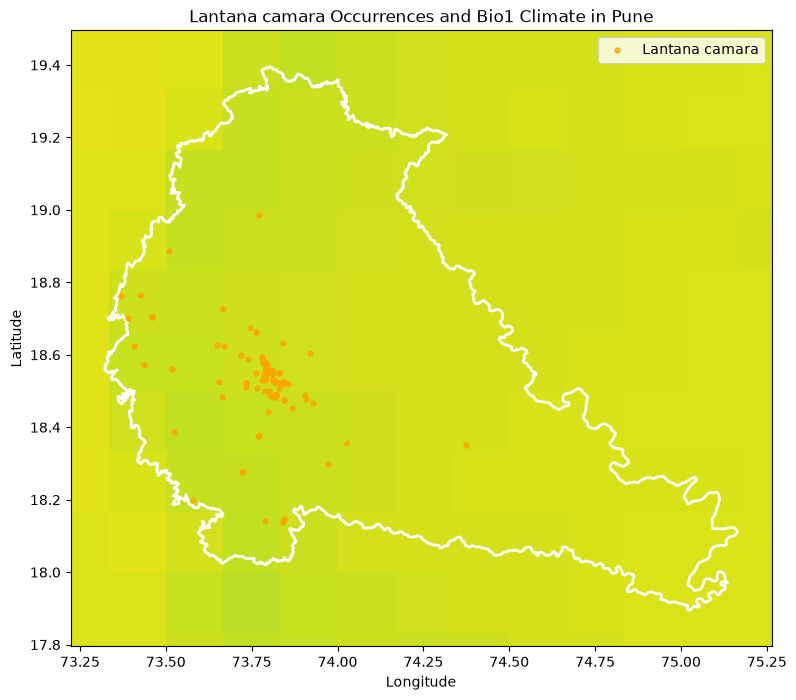

In [7]:
# 1. Load the background climate map and the occurrence data
background_tif = r"C:\Users\hibah\rd\image\wc2.1_10m_bio_1.tif"
df = pd.read_csv("lantana_full_dataset.csv")

# 2. Load the District GeoJSON file
# Replace this with the actual path to the file you just referenced
districts_geojson = gpd.read_file(r"C:/Users/hibah/rd/MAHARASHTRA_DISTRICTS.geojson")

# --- THE FIX: Filter for ONE specific district ---
# We use the 'dtname' column from your GeoJSON properties
district_name = 'Pune'
single_district = districts_geojson[districts_geojson['dtname'] == district_name]

# Ensure the coordinate system matches the raster
single_district = single_district.to_crs("EPSG:4326")

# 3. Convert occurrence DataFrame to a spatial GeoDataFrame
gdf_points = gpd.GeoDataFrame(
    df, 
    geometry=gpd.points_from_xy(df['longitude'], df['latitude']),
    crs="EPSG:4326"
)

# 4. Clip the points strictly to this single district
district_points = gpd.clip(gdf_points, single_district)
print(f"Total points strictly inside {district_name}: {len(district_points)}")

# 5. Set up the plot
fig, ax = plt.subplots(figsize=(10, 8))

# Layer 1: Background Climate Map
with rasterio.open(background_tif) as src:
    show(src, ax=ax, cmap='viridis', zorder=1)

# Layer 2: The Single District Boundary
single_district.plot(ax=ax, facecolor="none", edgecolor='white', linewidth=2, zorder=2)

# Layer 3: The clipped Lantana camara occurrences
if not district_points.empty:
    district_points.plot(
        ax=ax, 
        color='orange', 
        marker='.', 
        alpha=0.8, 
        markersize=50,  # Made dots slightly larger since we are zoomed in closer
        zorder=3, 
        label='Lantana camara'
    )

# 6. Zoom the map strictly to the district's borders
minx, miny, maxx, maxy = single_district.total_bounds

# Changed padding to 0.1 degrees since a district is much smaller than a state
ax.set_xlim(minx - 0.1, maxx + 0.1)
ax.set_ylim(miny - 0.1, maxy + 0.1)

plt.title(f"Lantana camara Occurrences and Bio1 Climate in {district_name}")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

if not district_points.empty:
    plt.legend()

plt.show()

In [8]:
df = pd.read_csv("lantana_full_dataset.csv")

# Convert occurrence data to spatial points
gdf_points = gpd.GeoDataFrame(
    df, 
    geometry=gpd.points_from_xy(df['longitude'], df['latitude']),
    crs="EPSG:4326"
)


india_districts = gpd.read_file(r"C:/Users/hibah/rd/INDIA_DISTRICTS.geojson")
india_districts = india_districts.to_crs("EPSG:4326")


joined_data = gpd.sjoin(gdf_points, india_districts, how="inner", predicate="intersects")


state_col = 'state'       
district_col = 'district' 


# Count for States
all_states_counts = joined_data[state_col].value_counts().reset_index()
all_states_counts.columns = ['state', 'Total_Occurrences']

# Count for Districts
all_districts_counts = joined_data.groupby([state_col, district_col]).size().reset_index(name='Total_Occurrences')
all_districts_counts = all_districts_counts.sort_values(by=['district', 'Total_Occurrences'], ascending=[True, False])

print("\n--- Top 5 States by Occurrence ---")
print(all_states_counts.head(5))

print("\n--- Preview of District Counts ---")
print(all_districts_counts.head(10))

# 5. Save the comprehensive lists
all_states_counts.to_csv("all_india_state_counts.csv", index=False)
all_districts_counts.to_csv("all_india_district_counts.csv", index=False)

print("\nSuccess! Full administrative counts saved to CSV files.")


--- Top 5 States by Occurrence ---
            state  Total_Occurrences
0          KERALA               2356
1      TAMIL NADU                610
2     MAHARASHTRA                428
3       KARNATAKA                309
4  ANDHRA PRADESH                239

--- Preview of District Counts ---
              state               district  Total_Occurrences
370     WEST BENGAL            >L|PUR DU>R                  2
319       TELANGANA               ADILABAD                  3
341   UTTAR PRADESH                   AGRA                  4
93          GUJARAT              AHMADABAD                 13
199     MAHARASHTRA             AHMEDNAGAR                  2
236         MIZORAM                 AIZAWL                 34
263       RAJASTHAN                  AJMER                 12
200     MAHARASHTRA                  AKOLA                  6
342   UTTAR PRADESH                ALIGARH                  1
2    ANDHRA PRADESH  ALLURI SITHARAMA RAJU                 28

Success! Full administr

In [9]:
df = pd.read_csv("lantana_full_dataset.csv")

# 2. Filter strictly for India
# This fulfills the "present only in India" requirement of your task
df_india = df[df['countryCode'] == 'IN'].copy()
print(f"Total India records to process: {len(df_india)}")

# 3. Prepare the coordinates for extraction
coords = [(x, y) for x, y in zip(df_india['longitude'], df_india['latitude'])]

# 4. Locate your 19 .tif files
# Pointing this to the folder where you kept your wc2.1_10m_bio files
tif_folder = r"C:\Users\hibah\rd\image" 
tif_files = glob.glob(os.path.join(tif_folder, "*.tif"))

print(f"Found {len(tif_files)} climate variables. Starting extraction...")

# 5. Loop through all 19 raster files and extract values
for tif_path in tif_files:
    # Get the file name (e.g., 'wc2.1_10m_bio_1') to use as the column name
    col_name = os.path.basename(tif_path).replace('.tif', '')
    
    with rasterio.open(tif_path) as src:
        # Extract the value for each coordinate
        extracted_values = [val[0] for val in src.sample(coords)]
        
        # Add it as a new column to the India dataframe
        df_india[col_name] = extracted_values
        
    print(f"Extracted data for: {col_name}")

# 6. Save the final completed dataset
output_filename = "India_Lantana_19_Bioclim_Values.csv"
df_india.to_csv(output_filename, index=False)

print(f"\nTask Complete! Final dataset saved to '{output_filename}'")

Total India records to process: 5643
Found 19 climate variables. Starting extraction...
Extracted data for: wc2.1_10m_bio_1
Extracted data for: wc2.1_10m_bio_10
Extracted data for: wc2.1_10m_bio_11
Extracted data for: wc2.1_10m_bio_12
Extracted data for: wc2.1_10m_bio_13
Extracted data for: wc2.1_10m_bio_14
Extracted data for: wc2.1_10m_bio_15
Extracted data for: wc2.1_10m_bio_16
Extracted data for: wc2.1_10m_bio_17
Extracted data for: wc2.1_10m_bio_18
Extracted data for: wc2.1_10m_bio_19
Extracted data for: wc2.1_10m_bio_2
Extracted data for: wc2.1_10m_bio_3
Extracted data for: wc2.1_10m_bio_4
Extracted data for: wc2.1_10m_bio_5
Extracted data for: wc2.1_10m_bio_6
Extracted data for: wc2.1_10m_bio_7
Extracted data for: wc2.1_10m_bio_8
Extracted data for: wc2.1_10m_bio_9

Task Complete! Final dataset saved to 'India_Lantana_19_Bioclim_Values.csv'


In [10]:

df_global = pd.read_csv("lantana_full_dataset.csv")

print(f"Total global records to process: {len(df_global)}")

# 2. Prepare the coordinates for extraction
# We are using the entire dataframe now, no country filters
coords = [(x, y) for x, y in zip(df_global['longitude'], df_global['latitude'])]

# 3. Locate your 19 .tif files
# Using your specific file path
tif_folder = r"C:\Users\hibah\rd\image" 
tif_files = glob.glob(os.path.join(tif_folder, "*.tif"))

print(f"Found {len(tif_files)} climate variables. Starting extraction (this may take a while)...")

# 4. Loop through all 19 raster files and extract values
for tif_path in tif_files:
    col_name = os.path.basename(tif_path).replace('.tif', '')
    
    with rasterio.open(tif_path) as src:
        # Extract the value for each coordinate globally
        extracted_values = [val[0] for val in src.sample(coords)]
        df_global[col_name] = extracted_values
        
    print(f"Extracted data for: {col_name}")

# 5. Clean out Ocean points
# To fulfill your task of removing points over the ocean, we filter out extreme "NoData" values.
# (Make sure 'wc2.1_10m_bio_1' perfectly matches the actual column name the script generates)
if 'wc2.1_10m_bio_1' in df_global.columns:
    df_global = df_global[df_global['wc2.1_10m_bio_1'] > -100].copy()
    print(f"Ocean points removed. Valid terrestrial records remaining: {len(df_global)}")

# 6. Save the final completed dataset
output_filename = "Global_Lantana_19_Bioclim_Values.csv"
df_global.to_csv(output_filename, index=False)

print(f"\nTask Complete! Final global dataset saved to '{output_filename}'")

Total global records to process: 122754
Found 19 climate variables. Starting extraction (this may take a while)...
Extracted data for: wc2.1_10m_bio_1
Extracted data for: wc2.1_10m_bio_10
Extracted data for: wc2.1_10m_bio_11
Extracted data for: wc2.1_10m_bio_12
Extracted data for: wc2.1_10m_bio_13
Extracted data for: wc2.1_10m_bio_14
Extracted data for: wc2.1_10m_bio_15
Extracted data for: wc2.1_10m_bio_16
Extracted data for: wc2.1_10m_bio_17
Extracted data for: wc2.1_10m_bio_18
Extracted data for: wc2.1_10m_bio_19
Extracted data for: wc2.1_10m_bio_2
Extracted data for: wc2.1_10m_bio_3
Extracted data for: wc2.1_10m_bio_4
Extracted data for: wc2.1_10m_bio_5
Extracted data for: wc2.1_10m_bio_6
Extracted data for: wc2.1_10m_bio_7
Extracted data for: wc2.1_10m_bio_8
Extracted data for: wc2.1_10m_bio_9
Ocean points removed. Valid terrestrial records remaining: 121952

Task Complete! Final global dataset saved to 'Global_Lantana_19_Bioclim_Values.csv'


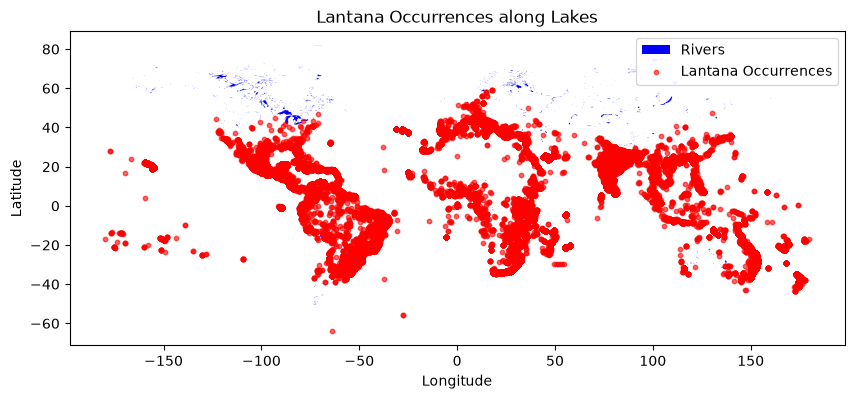

In [11]:
df = pd.read_csv("lantana_full_dataset.csv")
lakes = gpd.read_file(r"rd/ne_10m_lakes.shp")

df_clean = df.dropna(subset=['longitude', 'latitude'])

# 3. Convert the Pandas DataFrame into a GeoDataFrame
occurrences = gpd.GeoDataFrame(
    df_clean, 
    geometry=gpd.points_from_xy(df_clean.longitude, df_clean.latitude),
    crs="EPSG:4326" # Standard coordinate system for GPS data
)

# 4. Load your rivers (assuming you fixed the .shx issue!)

# 5. Plot them together
fig, ax = plt.subplots(figsize=(10, 10))
lakes.plot(ax=ax, color='blue', linewidth=1, label='Rivers')
occurrences.plot(ax=ax, color='red', markersize=10, alpha=0.6, label='Lantana Occurrences')

plt.title("Lantana Occurrences along Lakes")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.show()


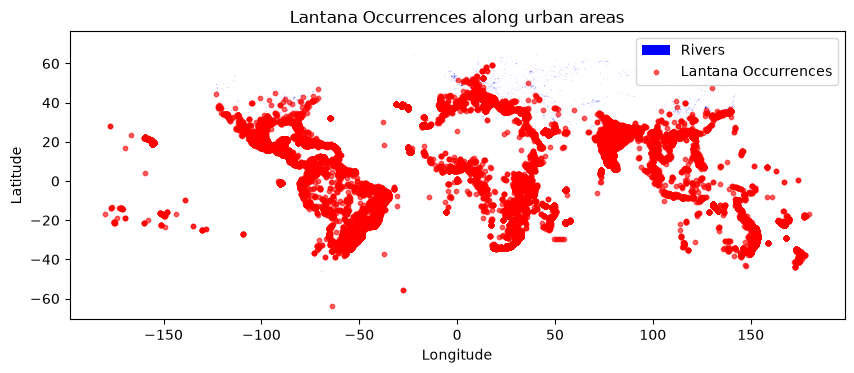

In [12]:
df = pd.read_csv("lantana_full_dataset.csv")
urban_areas = gpd.read_file(r"C:/Users/hibah/rd/ne_10m_urban_areas.shp")

df_clean = df.dropna(subset=['longitude', 'latitude'])

# 3. Convert the Pandas DataFrame into a GeoDataFrame
occurrences = gpd.GeoDataFrame(
    df_clean, 
    geometry=gpd.points_from_xy(df_clean.longitude, df_clean.latitude),
    crs="EPSG:4326" # Standard coordinate system for GPS data
)

# 5. Plot them together
fig, ax = plt.subplots(figsize=(10, 10))
urban_areas.plot(ax=ax, color='blue', linewidth=1, label='Rivers')
occurrences.plot(ax=ax, color='red', markersize=10, alpha=0.6, label='Lantana Occurrences')

plt.title("Lantana Occurrences along urban areas")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.show()

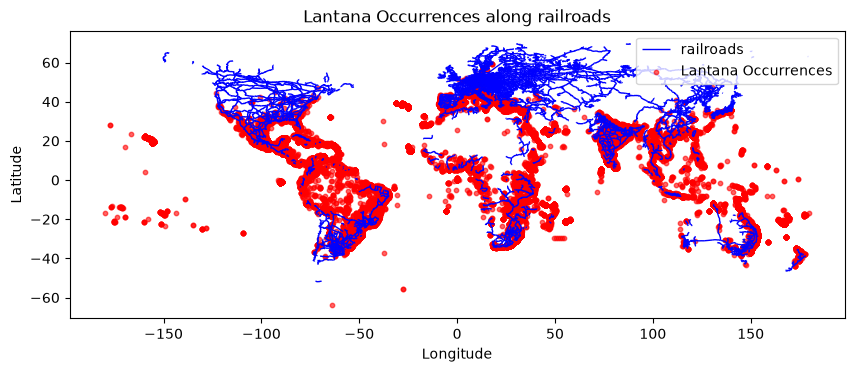

In [13]:
df = pd.read_csv("lantana_full_dataset.csv")
railroads = gpd.read_file(r"C:/Users/hibah/rd/ne_10m_railroads.shp")

df_clean = df.dropna(subset=['longitude', 'latitude'])

# 3. Convert the Pandas DataFrame into a GeoDataFrame
occurrences = gpd.GeoDataFrame(
    df_clean, 
    geometry=gpd.points_from_xy(df_clean.longitude, df_clean.latitude),
    crs="EPSG:4326" # Standard coordinate system for GPS data
)

# 5. Plot them together
fig, ax = plt.subplots(figsize=(10, 10))
railroads.plot(ax=ax, color='blue', linewidth=1, label='railroads')
occurrences.plot(ax=ax, color='red', markersize=10, alpha=0.6, label='Lantana Occurrences')

plt.title("Lantana Occurrences along railroads")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.show()


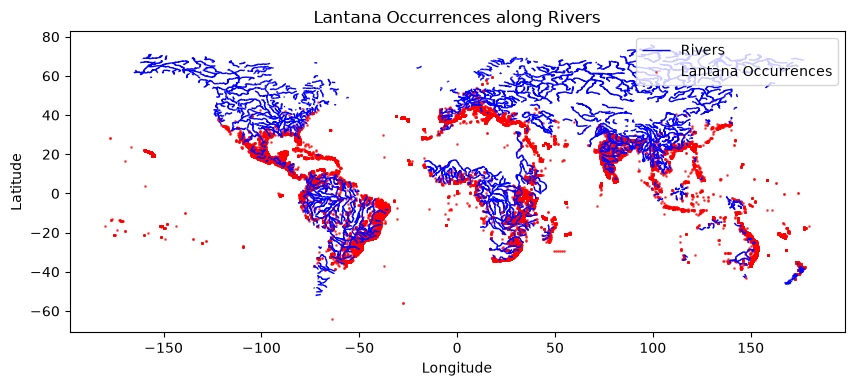

In [14]:
# 1. Load your CSV
df = pd.read_csv("lantana_full_dataset.csv")
river = gpd.read_file(r"rd/ne_10m_rivers_lake_centerlines.shp")
# 2. Drop rows missing coordinates 

df_clean = df.dropna(subset=['longitude', 'latitude'])

# 3. Convert the Pandas DataFrame into a GeoDataFrame
occurrences = gpd.GeoDataFrame(
    df_clean, 
    geometry=gpd.points_from_xy(df_clean.longitude, df_clean.latitude),
    crs="EPSG:4326" # Standard coordinate system for GPS data
)

# 5. Plot them together
fig, ax = plt.subplots(figsize=(10, 10))
river.plot(ax=ax, color='blue',edgecolor = "black", linewidth=1, label='Rivers')
occurrences.plot(ax=ax, color='red', markersize=1, alpha=0.6, label='Lantana Occurrences')

plt.title("Lantana Occurrences along Rivers")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.show()

In [15]:
print(df.columns.tolist())

['longitude', 'latitude', 'species', 'countryCode']


Total occurrences near lakes: 13


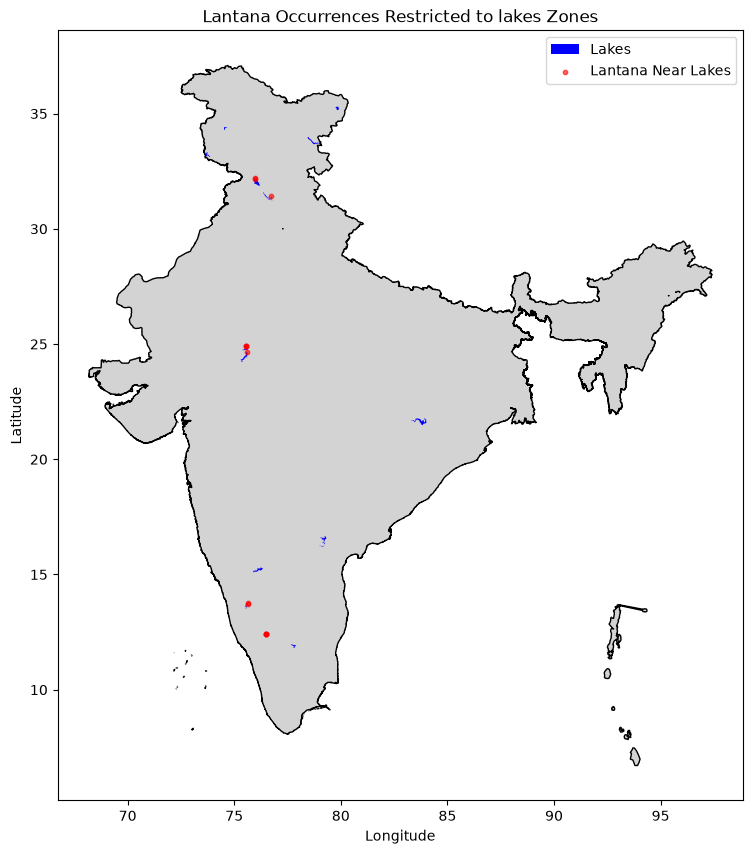

In [17]:
lakes = gpd.read_file(r"C:/Users/hibah/rd/ne_10m_lakes.shp")
lakes = lakes.to_crs(india.crs)
india_lakes = gpd.clip(lakes, india)
lakes_buffer_geometry = india_lakes.geometry.buffer(0.05)

# 2. Convert the raw buffer geometry into a GeoDataFrame
lakes_buffer = gpd.GeoDataFrame(geometry=lakes_buffer_geometry, crs=india_lakes.crs)

# 3. Clip the occurrences to only keep the ones inside the buffer zone
occurrences_near_lakes = gpd.clip(occurrences, lakes_buffer)
print(f"Total occurrences near lakes: {len(occurrences_near_lakes)}")
# 4. Plot everything together
fig, ax = plt.subplots(figsize=(10, 10))

# Plot the base map (using the dissolved outline from the previous step)
india_outline.plot(ax=ax, color='lightgrey', edgecolor='black', linewidth=1, zorder=1)

# Plot the rivers
india_lakes.plot(ax=ax, color='blue', linewidth=1, label='Lakes', zorder=2)

# Plot ONLY the filtered occurrences!
occurrences_near_lakes.plot(ax=ax, color='red', markersize=10, alpha=0.6, label='Lantana Near Lakes', zorder=3)

plt.title("Lantana Occurrences Restricted to lakes Zones")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.show()


Total occurrences near railroad : 1782


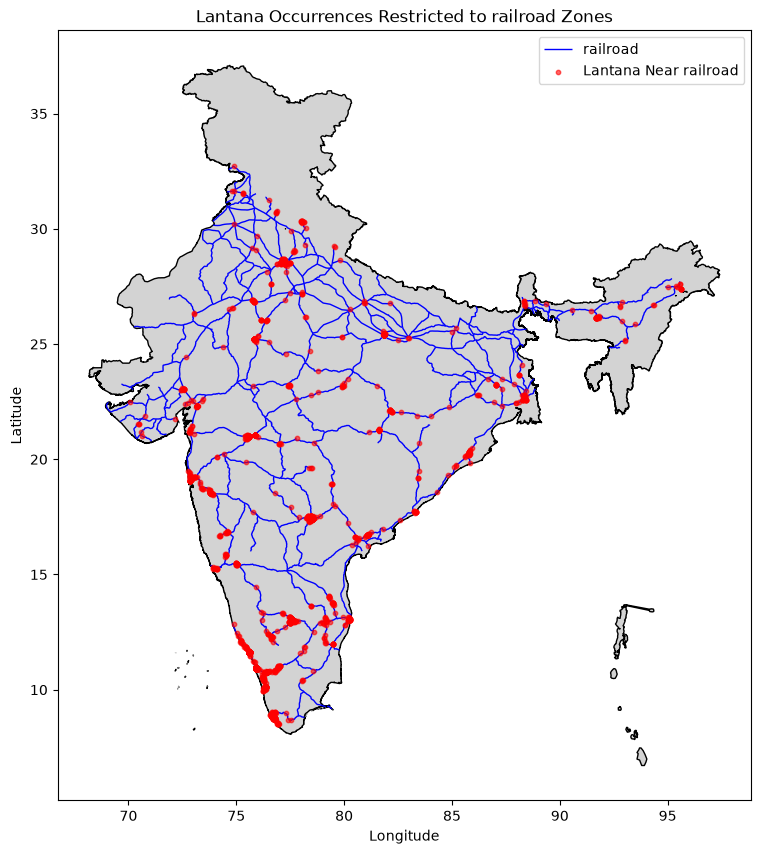

In [18]:
railroad = gpd.read_file(r"rd/ne_10m_railroads.shp")
railroad = railroad.to_crs(india.crs)
india_railroad = gpd.clip(railroad, india)
railroad_buffer_geometry = india_railroad.geometry.buffer(0.05)

# 2. Convert the raw buffer geometry into a GeoDataFrame
railroad_buffer = gpd.GeoDataFrame(geometry=railroad_buffer_geometry, crs=india_railroad.crs)

# 3. Clip the occurrences to only keep the ones inside the buffer zone
occurrences_near_railroad = gpd.clip(occurrences, railroad_buffer)
print(f"Total occurrences near railroad : {len(occurrences_near_railroad)}")
# 4. Plot everything together
fig, ax = plt.subplots(figsize=(10, 10))

# Plot the base map (using the dissolved outline from the previous step)
india_outline.plot(ax=ax, color='lightgrey', edgecolor='black', linewidth=1, zorder=1)

# Plot the rivers
india_railroad.plot(ax=ax, color='blue', linewidth=1, label='railroad', zorder=2)

# Plot ONLY the filtered occurrences!
occurrences_near_railroad.plot(ax=ax, color='red', markersize=10, alpha=0.6, label='Lantana Near railroad', zorder=3)

plt.title("Lantana Occurrences Restricted to railroad Zones")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.show()


Total occurrences near urbanarea: 1590


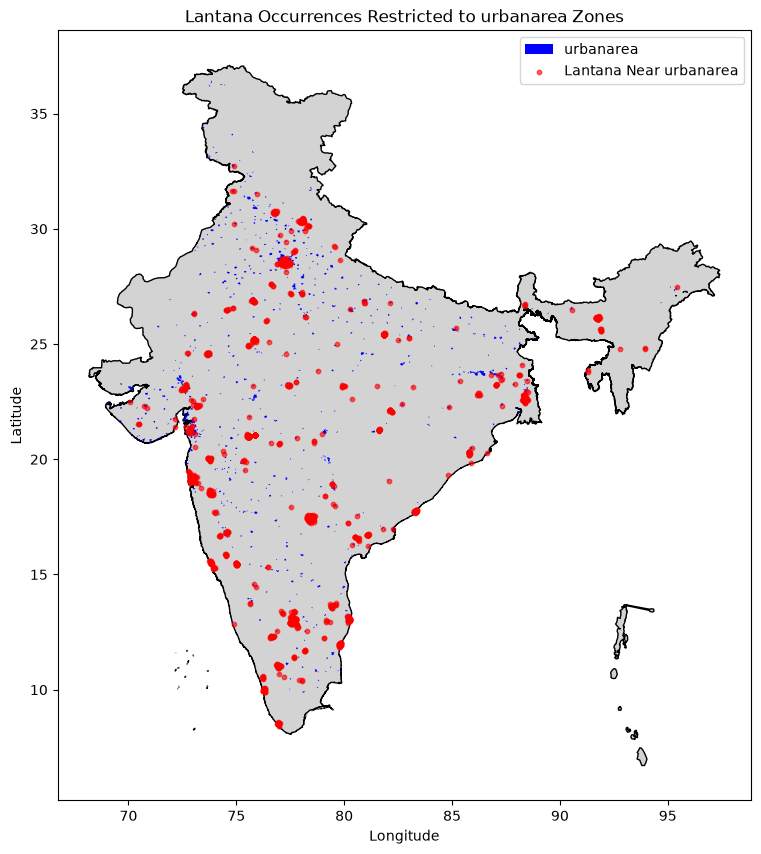

In [19]:
urbanarea = gpd.read_file(r"rd/ne_10m_urban_areas.shp")
urbanarea = urbanarea.to_crs(india.crs)
india_urbanarea = gpd.clip(urbanarea, india)
urbanarea_buffer_geometry = india_urbanarea.geometry.buffer(0.05)

# 2. Convert the raw buffer geometry into a GeoDataFrame
urbanarea_buffer = gpd.GeoDataFrame(geometry=urbanarea_buffer_geometry, crs=india_urbanarea.crs)

# 3. Clip the occurrences only to keep the ones inside the buffer zone
occurrences_near_urbanarea = gpd.clip(occurrences, urbanarea_buffer)
print(f"Total occurrences near urbanarea: {len(occurrences_near_urbanarea)}")
# 4. Plot everything together
fig, ax = plt.subplots(figsize=(10, 10))

# Plot the base map (using the dissolved outline from the previous step)
india_outline.plot(ax=ax, color='lightgrey', edgecolor='black', linewidth=1, zorder=1)

# Plot the rivers
india_urbanarea.plot(ax=ax, color='blue', linewidth=1, label='urbanarea', zorder=2)

# Plot ONLY the filtered occurrences!
occurrences_near_urbanarea.plot(ax=ax, color='red', markersize=10, alpha=0.6, label='Lantana Near urbanarea', zorder=3)

plt.title("Lantana Occurrences Restricted to urbanarea Zones")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.show()


In [20]:
# 1. Project your occurrences to metric (meters)
occ_metric = occurrences.to_crs(epsg=7755)

# 2. Project all your environmental layers to the exact same metric CRS
rivers_metric = india_rivers.to_crs(epsg=7755)
lakes_metric = india_lakes.to_crs(epsg=7755)
rail_metric = india_railroad.to_crs(epsg=7755)


# roads = gpd.read_file('path_to_roads.shp').to_crs(epsg=7755)
urban = india_urbanarea.to_crs(epsg=7755)

# 3. Helper function to calculate nearest distance and clean up
def get_nearest_distance(points, features, distance_col_name):
    # Find the nearest feature and calculate the distance
    joined = gpd.sjoin_nearest(points, features, distance_col=distance_col_name)
    
   
    # This line forces it to just keep the first one.
    joined = joined[~joined.index.duplicated(keep='first')]
    
    return joined[distance_col_name]

# 4. Apply the function to add new distance columns (in meters) to your dataset
occ_metric['dist_river_m'] = get_nearest_distance(occ_metric, rivers_metric, 'dist_river_m')
occ_metric['dist_lake_m'] = get_nearest_distance(occ_metric, lakes_metric, 'dist_lake_m')
occ_metric['dist_rail_m'] = get_nearest_distance(occ_metric, rail_metric, 'dist_rail_m')

#occ_metric['dist_road_m'] = get_nearest_distance(occ_metric, roads, 'dist_road_m')
occ_metric['dist_urban_m'] = get_nearest_distance(occ_metric, urban, 'dist_urban_m')

# 5. Convert meters to kilometers for readability
occ_metric['dist_river_km'] = occ_metric['dist_river_m'] / 1000
occ_metric['dist_lake_km'] = occ_metric['dist_lake_m'] / 1000
occ_metric['dist_rail_km'] = occ_metric['dist_rail_m'] / 1000
occ_metric['dist_urban_km'] = occ_metric['dist_urban_m'] / 1000
# 6. Check the first few rows to see your new data!
print(occ_metric.head())

     longitude   latitude         species countryCode  \
276  77.916069  30.080235  Lantana camara          IN   
277  76.412273  27.364386  Lantana camara          IN   
278  77.974960  30.286517  Lantana camara          IN   
878  88.363230  22.526991  Lantana camara          IN   
898  73.793196  18.563008  Lantana camara          IN   

                            geometry   dist_river_m    dist_lake_m  \
276  POINT (3801880.597 4663324.755)   27558.278808  164147.250928   
277   POINT (3651397.853 4370112.57)  122102.354885  276815.464185   
278  POINT (3807803.145 4685796.086)   24614.467720  151803.426461   
878  POINT (4843408.539 3865064.721)    5376.890807  448653.058672   
898  POINT (3354907.807 3423067.855)   24143.728212  432528.412878   

      dist_rail_m  dist_urban_m  dist_river_km  dist_lake_km  dist_rail_km  \
276  19678.317854  13636.668830      27.558279    164.147251     19.678318   
277  20256.891866  23684.392239     122.102355    276.815464     20.256892   
27

In [21]:
len(occurrences_near_urbanarea)

1590

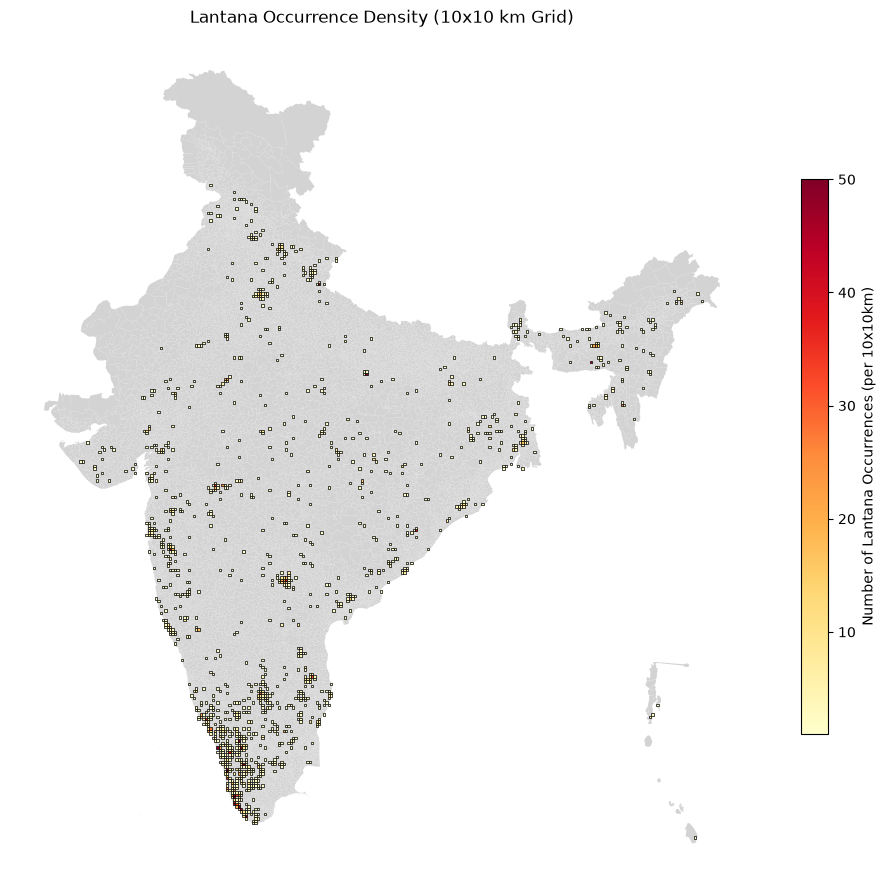

In [22]:
import numpy as np
import geopandas as gpd
from shapely.geometry import Polygon
import matplotlib.pyplot as plt

# 1. Ensure the bounding area (India) is also in the metric CRS
india_metric = india.to_crs(epsg=7755)
#
# 2. Get the bounding box of India (xmin, ymin, xmax, ymax)
xmin, ymin, xmax, ymax = india_metric.total_bounds

# 3. Define the cell size in meters (10 km = 10,000 meters)
cell_size = 10000 

# 4. Generate the grid cells
grid_cells = []
for x0 in np.arange(xmin, xmax, cell_size):
    for y0 in np.arange(ymin, ymax, cell_size):
        x1 = x0 + cell_size
        y1 = y0 + cell_size
        # Create a square polygon
        grid_cells.append(Polygon([(x0, y0), (x1, y0), (x1, y1), (x0, y1)]))

# 5. Convert the list of squares into a GeoDataFrame
grid = gpd.GeoDataFrame(geometry=grid_cells, crs="EPSG:7755")

# Assign a unique ID to each grid cell
grid['grid_id'] = grid.index

# 6. Perform a spatial join to match points to their enclosing grid cell

points_in_grid = gpd.sjoin(occ_metric, grid, how='inner', predicate='within')

# 7. Count how many points fall into each grid cell
counts = points_in_grid.groupby('grid_id').size().reset_index(name='occurrence_count')

# 8. Merge the counts back onto the grid map
grid_with_counts = grid.merge(counts, on='grid_id', how='left')

# Replace missing values (cells with no plants) with 0
grid_with_counts['occurrence_count'] = grid_with_counts['occurrence_count'].fillna(0)

# Filter out empty cells so we only plot areas that actually have Lantana
active_grid = grid_with_counts[grid_with_counts['occurrence_count'] > 0]

# Create the plot
fig, ax = plt.subplots(figsize=(12, 12))

# Plot the background map of India
# FIX: Set edgecolor='none' so the internal administrative lines disappear
india_metric.plot(ax=ax, color='lightgrey', edgecolor='none', zorder=1)

# Plot the grid cells, colored by their occurrence count
# FIX: Added zorder=2 to ensure the grid is drawn ON TOP of the base map
active_grid.plot(
    ax=ax, 
    column='occurrence_count', 
    cmap='YlOrRd',       # 'Yellow-Orange-Red' ensures the lowest values are clearly visible as yellow!
    vmax=50,             # Any cell with 50 or more plants will be dark red. 
    edgecolor='black', 
    linewidth=0.5,
    legend=True,
    zorder=2,
    legend_kwds={'label': "Number of Lantana Occurrences (per 10x10km)", 'shrink': 0.6}
)
plt.title("Lantana Occurrence Density (10x10 km Grid)")
ax.set_axis_off() 

plt.show()